In [28]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import random
from keras import Sequential
from tensorflow.keras.preprocessing.image import load_img

In [29]:
import os
path = "/mnt/c/Users/jiray/Documents/Project-ML-Pork-Safely/pork_dataset"
files = os.listdir(path)
train_path = os.path.join(path, "train set")
valid_path = os.path.join(path, "valid set")
test_path = os.path.join(path, "test set")
print("โฟลเดอร์ย่อยในพาธ:", files)

โฟลเดอร์ย่อยในพาธ: ['test set', 'train set', 'valid set']


In [45]:
IMAGE_SIZE = (256, 256)
BATCH_SIZE = 32

print("จำนวนไฟล์และคลาสใน train set : ")
train_dataset = tf.keras.utils.image_dataset_from_directory(
    train_path,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)
print("\n")

print("จำนวนไฟล์และคลาสใน valid set : ")
valid_dataset = tf.keras.utils.image_dataset_from_directory(
    valid_path,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)
print("\n")

print("จำนวนไฟล์และคลาสใน test set : ")
test_dataset = tf.keras.utils.image_dataset_from_directory(
    test_path,
    shuffle=True,
    batch_size=BATCH_SIZE,
    image_size=IMAGE_SIZE
)

จำนวนไฟล์และคลาสใน train set : 
Found 2100 files belonging to 2 classes.


จำนวนไฟล์และคลาสใน valid set : 
Found 300 files belonging to 2 classes.


จำนวนไฟล์และคลาสใน test set : 
Found 599 files belonging to 2 classes.


คลาสทั้งหมดในชุดข้อมูล: ['safe', 'unsafe']


W0000 00:00:1789734164.950533   27709 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 25166080 bytes after encountering the first element of size 25166080 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size


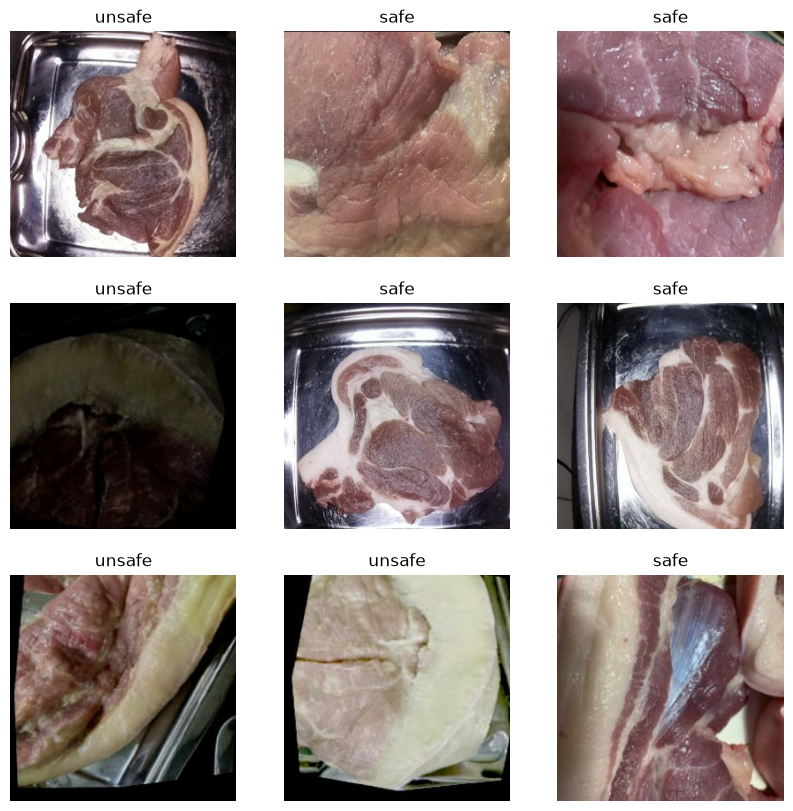

In [46]:
class_names = train_dataset.class_names
print("คลาสทั้งหมดในชุดข้อมูล:", class_names)
plt.figure(figsize=(10, 10)) 
for images, labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3, 3, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[labels[i]])
        plt.axis("off")

In [52]:
base_model = tf.keras.applications.ResNet50V2(input_shape=(IMAGE_SIZE[0],IMAGE_SIZE[1],3),include_top = False, weights = "imagenet")

W0000 00:00:1789734400.681411   27709 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 9.00MiB (rounded to 9437184)requested by op Mul
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1789734400.681850   27709 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1789734400.681861   27709 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 685, Chunks in use: 685. 171.2KiB allocated for chunks. 171.2KiB in use in bin. 44.9KiB client-requested in use in bin.
I0000 00:00:1789734400.681869   27709 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 181, Chunks in use: 181. 92.0KiB allocated for chunks. 92.0KiB in use in bin. 90.5KiB client-requested in use in bin.
I0000 00:00:1789734400.681873   27709 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 344, Chunks in use: 344. 345.0KiB 

ResourceExhaustedError: {{function_node __wrapped__Mul_device_/job:localhost/replica:0/task:0/device:GPU:0}} failed to allocate memory [Op:Mul] name: 

In [49]:
from tensorflow.keras.layers import Rescaling, GlobalAveragePooling2D, Dense, Input, BatchNormalization
from tensorflow.keras.models import Model

base_model.trainable = False

inputs = Input(shape=(256, 256, 3))
custom_ann = Rescaling(1./255)(inputs)
custom_ann = base_model(custom_ann)

custom_ann = GlobalAveragePooling2D()(custom_ann)
custom_ann = tf.keras.layers.Dense(16, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = BatchNormalization()(custom_ann)
custom_ann = tf.keras.layers.Dense(16, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = BatchNormalization()(custom_ann)
custom_ann = tf.keras.layers.Dense(8, activation='relu', kernel_initializer='random_normal')(custom_ann)
custom_ann = tf.keras.layers.Dense(4, activation='relu', kernel_initializer='random_normal')(custom_ann)
outputs = tf.keras.layers.Dense(units=1, activation='sigmoid')(custom_ann)

model = tf.keras.models.Model(inputs=inputs, outputs=outputs)
model.summary()

Model: "functional_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_10 (InputLayer)     │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling_6 (Rescaling)         │ (None, 256, 256, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50v2 (Functional)         │ (None, 8, 8, 2048)     │    23,564,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_9      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_40 (Dense)                │ (None, 16)             │        32,784 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_41 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16)             │            64 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_42 (Dense)                │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_43 (Dense)                │ (None, 4)              │            36 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_44 (Dense)                │ (None, 1)              │             5 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,598,161 (90.02 MB)

 Trainable params: 33,297 (130.07 KB)

 Non-trainable params: 23,564,864 (89.89 MB)

In [51]:
from keras.callbacks import ModelCheckpoint
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001), loss='binary_crossentropy',metrics=['accuracy'])
checkpointer = ModelCheckpoint(filepath='model.weights.best.keras',verbose=0,save_best_only=True)
history = model.fit(train_dataset, validation_data=valid_dataset, epochs=100, callbacks=[checkpointer])

Epoch 1/100


W0000 00:00:1789734305.574809   85682 prefetch_autotuner.cc:55] Prefetch autotuner tried to allocate 41942528 bytes after encountering the first element of size 41942528 bytes.This already causes the autotune ram budget to be exceeded. To stay within the ram budget, either increase the ram budget or reduce element size
I0000 00:00:1789734308.094753   28430 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_263597__.176
W0000 00:00:1789734308.468072   28430 bfc_allocator.cc:311] Allocator (GPU_0_bfc) ran out of memory trying to allocate 16.04MiB with freed_by_count=0. The caller indicates that this is not a failure, but this may mean that there could be performance gains if more memory were available.
W0000 00:00:1789734308.498305   28430 op_kernel.cc:1858] OP_REQUIRES failed at xla_ops.cc:602 : RESOURCE_EXHAUSTED: Out of memory while trying to allocate 16.04MiB. [tf-allocator-allocation-error='']
W0000 00:00:1789734308.499046   28430 local_rendezvous.cc:412] L

ResourceExhaustedError: Graph execution error:

Detected at node StatefulPartitionedCall defined at (most recent call last):
  File "<frozen runpy>", line 198, in _run_module_as_main

  File "<frozen runpy>", line 88, in _run_code

  File "/mnt/c/Users/jiray/ml/lib/python3.12/site-packages/ipykernel_launcher.py", line 18, in <module>

  File "/mnt/c/Users/jiray/ml/lib/python3.12/site-packages/traitlets/config/application.py", line 1080, in launch_instance

  File "/mnt/c/Users/jiray/ml/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 807, in start

  File "/mnt/c/Users/jiray/ml/lib/python3.12/site-packages/tornado/platform/asyncio.py", line 211, in start

  File "/usr/lib/python3.12/asyncio/base_events.py", line 645, in run_forever

  File "/usr/lib/python3.12/asyncio/base_events.py", line 1999, in _run_once

  File "/usr/lib/python3.12/asyncio/events.py", line 88, in _run

  File "/mnt/c/Users/jiray/ml/lib/python3.12/site-packages/ipykernel/kernelbase.py", line 621, in shell

11/12 ━━━━━━━━━━━━━━━━━━━━ 0s 169ms/step

W0000 00:00:1789731289.050501   28433 bfc_allocator.cc:502] Allocator (GPU_0_bfc) ran out of memory trying to allocate 1.27GiB (rounded to 1359217152)requested by op 
If the cause is memory fragmentation maybe the environment variable 'TF_GPU_ALLOCATOR=cuda_malloc_async' will improve the situation. 
Current allocation summary follows.
Current allocation summary follows.
I0000 00:00:1789731289.061204   28433 bfc_allocator.cc:1049] BFCAllocator dump for GPU_0_bfc
I0000 00:00:1789731289.061217   28433 bfc_allocator.cc:1056] Bin (256): 	Total Chunks: 457, Chunks in use: 457. 114.2KiB allocated for chunks. 114.2KiB in use in bin. 29.7KiB client-requested in use in bin.
I0000 00:00:1789731289.061232   28433 bfc_allocator.cc:1056] Bin (512): 	Total Chunks: 110, Chunks in use: 110. 56.2KiB allocated for chunks. 56.2KiB in use in bin. 55.0KiB client-requested in use in bin.
I0000 00:00:1789731289.061236   28433 bfc_allocator.cc:1056] Bin (1024): 	Total Chunks: 207, Chunks in use: 207. 208.0KiB 

12/12 ━━━━━━━━━━━━━━━━━━━━ 43s 4s/step 


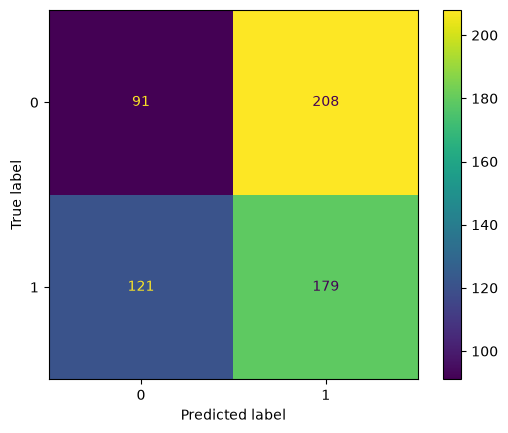

In [38]:
from sklearn.metrics import confusion_matrix, classification_report, confusion_matrix, ConfusionMatrixDisplay
import seaborn as sns
import matplotlib.pyplot as plt

y_pred = model.predict(test_dataset)
y_pred = (y_pred > 0.5).astype("int32")

y_true = []
for images, labels in test_dataset:
    y_true.extend(labels.numpy())
y_true = np.array(y_true)

cm = ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred))

cm.plot()
plt.show()

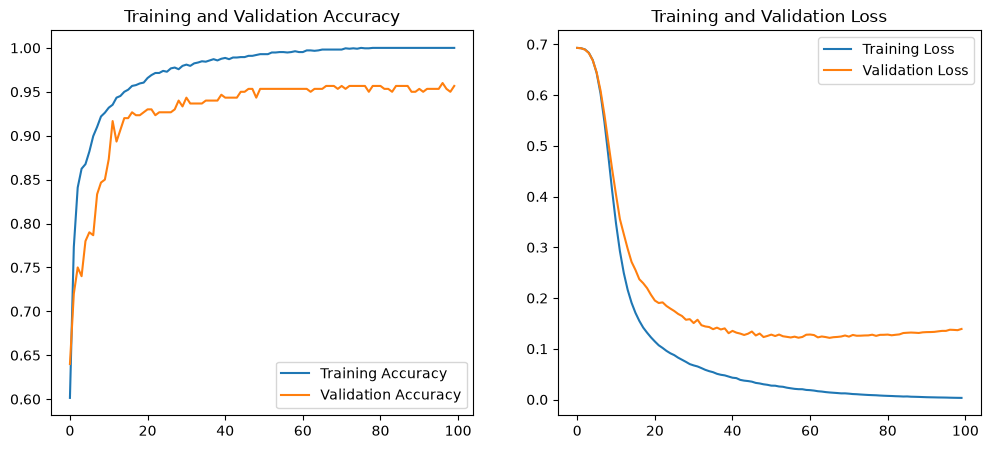

In [39]:
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(12, 5))

# กราฟความแม่นยำ (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')

# กราฟความสูญเสีย (Loss)
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.show()